---
# Project D: Photometric redshifts: when a point estimate isn't enough

##  Motivation

Photometric redshift estimation has a famous problem: **color–redshift degeneracy** (galaxies at very different redshifts can have a nearly identical color) so the true posterior $p(z\mid\text{colors})$ is often **multi-modal**. A single number with an error bar is genuinely misleading here. This makes this project the perfect example to show how adaptable conditional probabilities work.

The goal here is to predict the posterior $p(z\mid\text{colors})$ for quasars - not just a point estimate. First we build a Gaussian mean–variance baseline, which is provably unable to represent a bimodal posterior, next, a mixture-density network (MDN), which can. We then check both for **calibration** and give **explicit worked examples** of bimodal posteriors.

### The work flow

First we build a Gaussian mean–variance baseline, which is provably unable to represent a bimodal posterior. Next, we will use a mixture-density network (MDN), which with proper training, should be able to yield a physical accurate posterior. We then will check both for **calibration** and give **explicit worked examples** of bimodal posteriors.

### Getting the data for Project D

Project D uses a real **SDSS quasar** photometric-redshift sample. Quasars are the right choice
because their ugriz colors are genuinely *degenerate* (different redshifts give nearly identical
colors), so the true posterior $p(z\mid\text{colors})$ is often **multi-modal**, which is exactly the
phenomenon this project is about. 

In [2]:
import numpy as np, pandas as pd, io, urllib.parse, urllib.request

# SDSS quasar photo-z sample. Two ways to get it:
#  Option 1 (reliable): paste SDSS_QSO_SQL into the web form
#     https://skyserver.sdss.org/dr18/SearchTools/sql  -> choose CSV -> save as sdss_qso_photoz.csv
#  Option 2 (from Python): call download_sdss_qso() below.
SDSS_QSO_SQL = """
SELECT TOP 50000
    s.z AS redshift,
    p.dered_u AS u, p.dered_g AS g, p.dered_r AS r, p.dered_i AS i, p.dered_z AS z
FROM SpecObj AS s
JOIN PhotoObj AS p ON s.bestobjid = p.objid
WHERE s.class = 'QSO' AND s.zWarning = 0 AND p.clean = 1
  AND p.dered_u BETWEEN 0 AND 30 AND p.dered_g BETWEEN 0 AND 30
  AND p.dered_r BETWEEN 0 AND 30 AND p.dered_i BETWEEN 0 AND 30 AND p.dered_z BETWEEN 0 AND 30
  AND s.z BETWEEN 0 AND 5
"""

def download_sdss_qso(path="sdss_qso_photoz.csv"):
    """Query SkyServer's DR18 CSV endpoint and save the quasar sample. If it fails (busy / no network),
    use the web form above and save the CSV to `path` yourself."""
    base = "https://skyserver.sdss.org/dr18/SkyServerWS/SearchTools/SqlSearch"
    url = base + "?" + urllib.parse.urlencode({"cmd": SDSS_QSO_SQL, "format": "csv"})
    with urllib.request.urlopen(url, timeout=180) as resp:
        text = resp.read().decode()
    lines = [ln for ln in text.splitlines() if ln and not ln.startswith("#")]   # strip #Table comment
    open(path, "w").write("\n".join(lines))
    print(f"saved {path}  ({max(len(lines)-1,0)} rows)")
    return path

def load_quasar_photoz(path="sdss_qso_photoz.csv"):
    """Load the quasar CSV, clean bad rows, return (colors, spec_z).
    colors = (u-g, g-r, r-i, i-z)  -> model inputs;  spec_z = spectroscopic redshift -> target."""
    raw = open(path).read()
    lines = [ln for ln in raw.splitlines() if ln and not ln.startswith("#")]
    d = pd.read_csv(io.StringIO("\n".join(lines)))
    mags = ["u", "g", "r", "i", "z"]
    d = d[(d[mags] > -100).all(axis=1) & (d[mags] < 40).all(axis=1)]   # drop -9999 sentinels
    d = d[(d["redshift"] > 0) & (d["redshift"] < 5.0)]                 # physical quasar redshifts
    colors = np.stack([d["u"]-d["g"], d["g"]-d["r"], d["r"]-d["i"], d["i"]-d["z"]], axis=1).astype(np.float32)
    zspec = d["redshift"].to_numpy().astype(np.float32)
    print(f"{len(zspec)} quasars | colors {colors.shape} (u-g, g-r, r-i, i-z) | z in [{zspec.min():.2f}, {zspec.max():.2f}]")
    return colors, zspec

# download_sdss_qso()                       # run once, then comment out
print("SDSS quasar photo-z helpers ready: download_sdss_qso() then load_quasar_photoz().")

SDSS quasar photo-z helpers ready: download_sdss_qso() then load_quasar_photoz().


### Multi-modality check (training-free, motivates the whole project)

Before building a posterior model, we confirm the data actually contains the **color–redshift degeneracy** which justifies a multi-modal posterior. The check is training-free: the redshifts of a quasar's nearest neighbors **in colour space** are samples from the empirical posterior $p(z\mid\text{colors})$. If those neighbor-redshifts split into at least two separated clusters, the posterior will be multi-modal. We report the **fraction of objects** that are multi-modal and plot a few example neighbor-redshift histograms. (A clearly non-zero fraction, accompanied by visibly bimodal examples, serves as motivation for the project.)

50000 quasars | colors (50000, 4) (u-g, g-r, r-i, i-z) | z in [0.27, 5.00]
multi-modal fraction: 19.5%  (9750 of 50000 quasars)
a clearly non-zero fraction with bimodal examples below


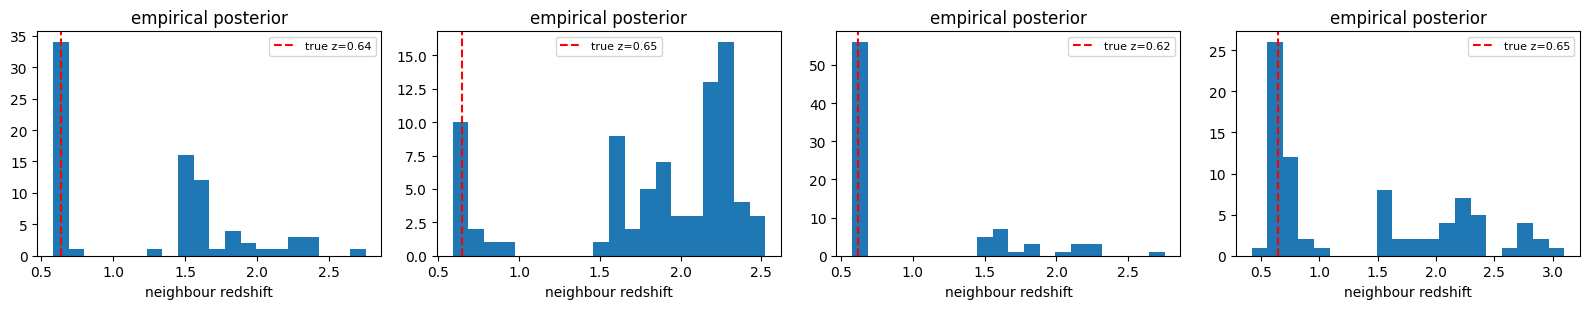

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

colors, zspec = load_quasar_photoz()        # uses the CSV you downloaded above

def multimodality_report(colors, zspec, k=80, gap=0.5, mass=0.15):
    """Flag an object multi-modal if its k colour-space neighbours' redshifts split into two clusters
    separated by a gap > `gap`, each holding at least a fraction `mass` of the neighbours."""
    Cs = (colors - colors.mean(0)) / (colors.std(0) + 1e-9)         # standardize colours
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(Cs).kneighbors(Cs)
    flags = np.zeros(len(zspec), bool); examples = []
    for q in range(len(zspec)):
        zn = np.sort(zspec[idx[q, 1:]])                             # neighbour redshifts (drop self)
        g = np.diff(zn); p = g.argmax()
        if g[p] > gap and min(p + 1, len(zn) - (p + 1)) >= mass * k:
            flags[q] = True; examples.append(q)
    return flags, examples, idx

flags, examples, idx = multimodality_report(colors, zspec)
print(f"multi-modal fraction: {flags.mean():.1%}  ({flags.sum()} of {len(flags)} quasars)")
print("a clearly non-zero fraction with bimodal examples below")

# plot neighbour-redshift histograms for a few flagged (bimodal) objects
show = examples[:4] if len(examples) >= 4 else examples
if show:
    fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 3.2), squeeze=False)
    for ax, q in zip(axes[0], show):
        zn = zspec[idx[q, 1:]]
        ax.hist(zn, bins=20)
        ax.axvline(zspec[q], color='r', ls='--', label=f"true z={zspec[q]:.2f}")
        ax.set_xlabel("neighbour redshift"); ax.set_title("empirical posterior"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("No clearly-bimodal objects found at these thresholds — try k=120, or loosen gap/mass,")
    print("or the sample may be too unimodal for the multi-modal showcase (consider a wider z range).")

Roughly 1 in 5 objects has a clearly bimodal neighbourhood - separated, substantial clusters of plausible redshifts, with the true value sitting in just **one** of them. That's exactly what a single mean+error-bar cannot represent. This is the concrete justification for the flexible posterior we will use in this project.

## Pre-training 

### Train / validation / test split and preprocessing

70% (train) / 15% (validation) / 15% (testing) split. 

The validation set is to be used with the early stopping mechanism to prevent variance collapse. The testing set is later used to evaluate the MDN while ensuring there's no leakage.

Colors are standardized using **training-set** statistics only (every data which will be fed into the trained model will be compared to the same standard).

Redshift $z$ is left in its natural units (0–4) since the loss functions below are already scale-aware (mean–variance / mixture likelihoods).

In [ ]:
import torch, torch.nn as nn

torch.manual_seed(0); np.random.seed(0)
N = len(zspec)
# manual split to 3 groups since "sklearn.train_test_split" (which shuffles and split) only splits to 2.
perm = np.random.permutation(N) # an array of N shuffled indices.
n_tr, n_va = int(0.7*N), int(0.15*N)
tr, va, te = perm[:n_tr], perm[n_tr:n_tr+n_va], perm[n_tr+n_va:] 

# standardization - rescaling each color feature to be centered at 0 with unit spread
mu_c, sd_c = colors[tr].mean(0), colors[tr].std(0) # computes the mean and std of each of the 4 color columns (u-g, g-r,...), over the training rows only

print(mu_c.shape, sd_c.shape)

# we standardize each set by the same scale taken from the training set.
Xtr = (colors[tr]-mu_c)/sd_c
Xva = (colors[va]-mu_c)/sd_c
Xte = (colors[te]-mu_c)/sd_c

ytr, yva, yte = zspec[tr], zspec[va], zspec[te] # the actual redshifts according to each sets' indices. 

# converting to tensors
Xtr_t=torch.tensor(Xtr); ytr_t=torch.tensor(ytr).unsqueeze(1)
Xva_t=torch.tensor(Xva); yva_t=torch.tensor(yva).unsqueeze(1)
Xte_t=torch.tensor(Xte); yte_t=torch.tensor(yte).unsqueeze(1)
print(f"train {len(tr)} val {len(va)} test {len(te)}")

(4,) (4,)
train 35000 val 7500 test 7500


---
## Model 1 - Gaussian Baseline

### The Gaussian Baseline

A simple mean–variance network: outputs are $\mu(x)$ and $\log\left(\sigma^2(x)\right)$. The network is trained by Gaussian negative log-likelihood ('nll'). This is the "point estimate + calibrated error bar" approach. Its posterior is, by construction, a single symmetric bump - although it can be wide, it can never be two-peaked.

In [ ]:
# Creating the network
class PosteriorNet(nn.Module):
    '''Gaussian posterior p(target | x): outputs mean and log-variance.'''
    def __init__(self, in_dim, hidden=64):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
        self.mu = nn.Linear(hidden, 1); self.logvar = nn.Linear(hidden, 1)
    def forward(self, x): z = self.body(x); return self.mu(z), self.logvar(z)

# defining the loss function
def gaussian_nll(mu, logvar, target): # Negative Log-Likelihood loss function
    return (0.5 * logvar + 0.5 * (target - mu) ** 2 / torch.exp(logvar)).mean()

# train model which will work for *any* model + loss function
# both  PosteriorNet + gaussian_nll and later MixtureDensityNet + mdn_nll
# flexible hyperparameters
def train_model(model, loss_fn, epochs=600, lr=2e-3, wd=1e-5, patience=50, batch=512):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, threshold=1e-3)

    # set up for early stopping
    min_valid_loss = np.inf
    badepochs = 0
    best_state = None

    n = Xtr_t.shape[0]

    # outerloop - epochs
    for t in range(epochs):
        model.train()
        perm_e = torch.randperm(n)
        train_loss = 0

        # inner loop - mini batches
        for i in range(0, n, batch):
            b = perm_e[i:i+batch]
            optimizer.zero_grad()
            out = model(Xtr_t[b])
            loss = loss_fn(*out, ytr_t[b])
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        
        model.eval()
        with torch.no_grad():
            valid_loss = loss_fn(*model(Xva_t), yva_t).item()
        if t % 10 == 0:
            print('Epoch %3i: train loss %.4f  validation loss %.4f' %
                  (t, train_loss / (n // batch + 1), valid_loss))
        scheduler.step(valid_loss)

        # early-stopping check
        if valid_loss > min_valid_loss*(1-1e-4):
            badepochs += 1
        else:
            min_valid_loss = valid_loss
            badepochs = 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if badepochs == patience:
            print('Finished training')
            break

    model.load_state_dict(best_state)
    return model, min_valid_loss

# training the network
gauss_base = PosteriorNet(4)
gauss_base, g_best = train_model(gauss_base, gaussian_nll)
print(f"Gaussian PosteriorNet: best val NLL = {g_best:.4f}")

Epoch   0: train loss 0.5176  validation loss 0.1350
Epoch  10: train loss -0.3817  validation loss -0.3541
Epoch  20: train loss -0.4319  validation loss -0.4031
Epoch  30: train loss -0.4478  validation loss -0.4125
Epoch  40: train loss -0.4643  validation loss -0.4121
Epoch  50: train loss -0.4800  validation loss -0.4203
Epoch  60: train loss -0.4847  validation loss -0.4242
Epoch  70: train loss -0.4862  validation loss -0.4241
Epoch  80: train loss -0.4841  validation loss -0.4241
Epoch  90: train loss -0.4858  validation loss -0.4241
Finished training
Gaussian PosteriorNet: best val NLL = -0.4267


The training loop written here is adaptable for both models and therefore will be used for the MDN next.

## Model 2 - MDN

A $K$-component Gaussian-mixture network: $q_\phi(z\mid x)=\sum_k \pi_k(x)\,\mathcal N(z;\mu_k(x),\sigma_k^2(x))$,
trained by mixture negative log-likelihood. With $K>1$ components it can place separate peaks at the
low-$z$ and high-$z$ solutions of a degenerate object (the quasar). 

Two regularisers prevent the variance-collapse overconfidence:

1. A variance floor ($\sigma^2 \mathrel{+}= 0.03^2$) 
2. Light weight decay. 

We break the initial symmetry between the $K$ components by seeding their mean-biases at the 10th–90th percentiles of the training redshifts.

I chose $K=3$ as the multimodality check found a clear two-branch degeneracy, so 2 is the minimum, but I used 3 to give the model a little headroom for objects that aren't cleanly bimodal, without going as far as an arbitrary larger *K* which increases variance-collapse risk for no evidence-based reason.

In [6]:
class MixtureDensityNet(nn.Module):
    '''Flexible (multi-modal) posterior: a K-component Gaussian mixture p(target | x).
    REGULARISE against variance collapse: variance floor + weight decay + early stopping.'''
    def __init__(self, in_dim, K=3, hidden=64):
        super().__init__()
        self.K = K
        self.body = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
        self.pi = nn.Linear(hidden, K); self.mu = nn.Linear(hidden, K); self.logvar = nn.Linear(hidden, K)
    def forward(self, x):
        z = self.body(x); return torch.log_softmax(self.pi(z), -1), self.mu(z), self.logvar(z)

var_floor = 0.03 ** 2
def mdn_nll(log_pi, mu, logvar, target, var_floor):
    var = torch.exp(logvar) + var_floor
    comp = -0.5 * torch.log(var) - 0.5 * (target - mu) ** 2 / var - 0.5 * np.log(2 * np.pi)
    return -(torch.logsumexp(log_pi + comp, -1)).mean()

# 3 separate Gaussian "guesses" per quasar
mdn = MixtureDensityNet(4, K=3)
with torch.no_grad():
    qs = np.quantile(ytr, np.linspace(0.1, 0.9, mdn.K)).astype(np.float32) # mdn.K = 3, np.linspace(0.1, 0.9, 3) -> [0.1, 0.5, 0.9] quantiles -> 3 values of the given quantiles from 'ytr'
    # give each of the K components a different starting mean (10th/50th/90th percentile of the training redshifts) instead of all starting near the same random value
    # without this, components have no reason to specialize into separate low-z/high-z peaks
    mdn.mu.bias.copy_(torch.tensor(qs))  # break initial symmetry between components

# training the network with the same training model we built.
mdn, m_best = train_model(mdn, lambda lp,mu,lv,t: mdn_nll(lp,mu,lv,t, var_floor))
print(f"MixtureDensityNet: best val NLL = {m_best:.4f}")

Epoch   0: train loss 1.2378  validation loss 0.7213
Epoch  10: train loss 0.0074  validation loss -0.0092
Epoch  20: train loss -0.0721  validation loss -0.0751
Epoch  30: train loss -0.0996  validation loss -0.0771
Epoch  40: train loss -0.1417  validation loss -0.1120
Epoch  50: train loss -0.1593  validation loss -0.1379
Epoch  60: train loss -0.1953  validation loss -0.1490
Epoch  70: train loss -0.1993  validation loss -0.1490
Epoch  80: train loss -0.2037  validation loss -0.1505
Epoch  90: train loss -0.2038  validation loss -0.1505
Epoch 100: train loss -0.2026  validation loss -0.1505
Epoch 110: train loss -0.2041  validation loss -0.1505
Epoch 120: train loss -0.2020  validation loss -0.1505
Finished training
MixtureDensityNet: best val NLL = -0.1512


## Evaluations

### Evaluation 1 - Point-Estimate Metric

Standard photo-z point metric:
$$\Delta z_i = \frac{(z_\text{pred,i}-z_\text{true,i})}{(1+z_\text{true,i})}$$

where mean of absolute error:

$$\text{MAE} = \frac{1}{N} \sum_{i=1}^{N} \vert{}\Delta z_i\vert{} = \frac{1}{N} \sum_{i=1}^{N} \left\vert{} \frac{z_{\text{pred}, i} - z_{\text{true}, i}}{1 + z_{\text{true}, i}} \right\vert{}$$

The outliers obtain: 
$$|\Delta z|>0.15$$

In [ ]:
gauss_base.eval()
mdn.eval()

# predictions of testing set (Gaussian baseline and MDN)
with torch.no_grad():
    # Gaussian baseline
    g_mu, g_logvar = gauss_base(Xte_t)
    # numpy array + flattening 
    g_mu = g_mu.numpy().ravel()
    # log(σ²) -> exp(log(σ²)) = σ² -> σ = sqrt(σ²)
    g_sig = np.sqrt(np.exp(g_logvar.numpy().ravel()))

    # MDN
    log_pi, mdn_mu, mdn_logvar = mdn(Xte_t)
    # log(π) -> π = exp(log(π)) - of each object
    pi = torch.exp(log_pi).numpy()
    mdn_mu_np = mdn_mu.numpy()
    # log(σ²) -> exp(log(σ²)) = σ² - of each object
    mdn_var = np.exp(mdn_logvar.numpy()) + var_floor

# accepts predictions and true values and returns the MAE and the outlier fraction
def point_metrics(pred, y, name):
    dz = (pred - y) / (1 + y)
    # mean of all absolute errors
    mae = np.mean(np.abs(dz))
    # outlier definition
    outlier = np.mean(np.abs(dz) > 0.15) # mean = count of true (1) \ total count (1+0+1+...) = fraction of outliers
    print(f"{name:22s}  MAE(Dz)={mae:.4f}   outlier frac (|Dz|>0.15) = {outlier:.3%}")

# predicted vs true redshift
point_metrics(g_mu, yte, "Gaussian baseline")
point_metrics((pi*mdn_mu_np).sum(1), yte, "MDN (mixture mean)") # this weight averages the mdn predictions

Gaussian baseline       MAE(Dz)=0.1501   outlier frac (|Dz|>0.15) = 30.347%
MDN (mixture mean)      MAE(Dz)=0.1460   outlier frac (|Dz|>0.15) = 29.307%


The outlier fraction is high (~29–30%) for both models - quasar photo-z from four broadband colors alone is a genuinely hard, degenerate problem, and this is in line with the literature (QSO photo-z from `ugriz` colors typically shows outlier rates well above the ~5–10% seen for galaxies, precisely because of the degeneracy this project is about). The two models are close on the point metric - again expected, since **a point estimate can't reflect the fact that one model *knows* it's choosing between two real options** while the other doesn't. Averaging a two-peaked distribution into one number throws away the one thing the MDN is actually good at, so this type of estimation heavily underestimates the MDN.

### Evaluation 2 - Calibration

In [8]:
# ---------- Regression calibration: calibration curve + coverage ----------
from scipy.stats import norm
def regression_calibration(y_true, mu, sigma, n_levels=11):
    '''Given predicted Gaussian posteriors N(mu, sigma^2) and true y, return the
    calibration curve (nominal vs observed coverage), the 1-sigma & 2-sigma central
    coverage, and a single calibration-error number (mean |observed - nominal|).'''
    y_true, mu, sigma = map(np.asarray, (y_true, mu, sigma))
    nominal = np.linspace(0.0, 1.0, n_levels)
    observed = np.array([(y_true <= mu + sigma * norm.ppf(q)).mean() if 0 < q < 1 else float(q == 1.0)
                         for q in nominal])
    z = (y_true - mu) / sigma
    cov_1s = float((np.abs(z) <= 1).mean()); cov_2s = float((np.abs(z) <= 2).mean())
    cal_err = float(np.mean(np.abs(observed - nominal)))
    return nominal, observed, cov_1s, cov_2s, cal_err

def plot_regression_calibration(y_true, mu, sigma, title="Regression calibration"):
    nominal, observed, c1, c2, cal_err = regression_calibration(y_true, mu, sigma)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot([0, 1], [0, 1], 'k--', label="perfect calibration")
    ax.plot(nominal, observed, 'o-', label="model")
    ax.set_xlabel("nominal coverage"); ax.set_ylabel("observed coverage")
    ax.set_title(f"{title}\n1σ cov={c1:.2f} (want 0.68), 2σ cov={c2:.2f} (want 0.95)")
    ax.legend(); ax.set_aspect("equal"); plt.tight_layout(); plt.show()
    return c1, c2, cal_err

print("Calibration helpers ready: plot_reliability(...) and plot_regression_calibration(...).")

Calibration helpers ready: plot_reliability(...) and plot_regression_calibration(...).


The Gaussian baseline's calibration can be checked with a simple coverage curve, since it always predicts one symmetric peak. The MDN's posterior can be multi-peaked, so there's no single "how many sigma away" to compare against.

PIT (probability integral transform) is the generalization made for MDN, since a plain coverage curve like the Gaussian's assumes one symmetric peak, and the MDN's posterior is a mixture.

That's why, for a given quasar, we use **PIT value** which is the CDF evaluated at the true redshift:
$$u = F_{\text{MDN}}(z_{\text{true}} \mid \text{colors})$$

where $F_{\text{MDN}}$ is the mixture's CDF. 
For example - PIT < 0.1 is just another way of writing "truth < model's stated 10th percentile."

If the model is well calibrated, the true redshift is equally likely to land anywhere within its predicted distribution, so across the whole test set the PIT values should be **uniformly distributed between 0 and 1**.

An under-confident model yields a much wider range than necessary so the 10th percentile have a more extreme value. The true value falls below that extreme, model-claimed 10th-percentile threshold **less** than 10% of the time and the same thing happens at the top 10% - the model's 90th-percentile threshold is also unnecessarily extreme, so truth exceeds it less than 10% of the time too. Both tails end up underfilled relative to what the model claimed.

The opposite happens in an over-confident model where the truth falls mostly in the tails for each quasar (zeros and ones) thus we get that the PIT values are mostly at the ends of the histogram.

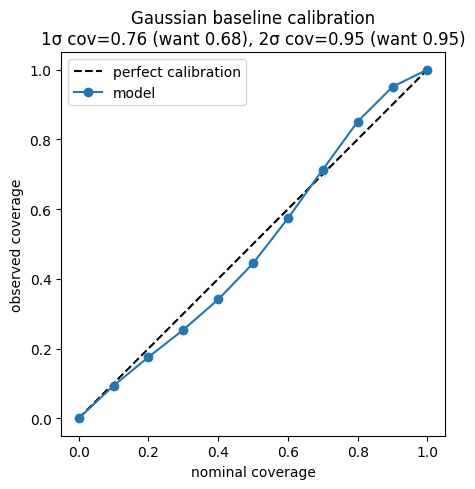

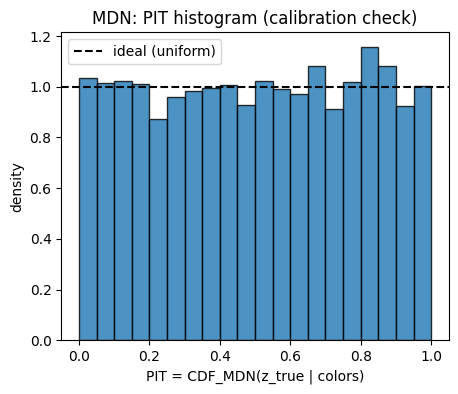

In [ ]:
from scipy.special import erf

c1, c2, cal_err = plot_regression_calibration(yte, g_mu, g_sig, title="Gaussian baseline calibration")

def mixture_cdf(y, pi, mu, var):
    '''For each quasar, the fraction of the MDN's predicted probability mass
    that lies below the true redshift y -- this is the PIT value.'''
    z_sc = (y[:, None] - mu) / np.sqrt(var)  # the z-score of the true redshift for each of the K guesses - how many standard deviations away the real redshift is from this component's center.
    Phi = 0.5 * (1 + erf(z_sc / np.sqrt(2))) # turn that distance into each component's individual CDF at the true value
    return (pi * Phi).sum(1) # the full predicted distribution's CDF is just the same weighted sum of each component's CDF.
    # Each component's CDF gets multiplied by how much that component is trusted then summed, yielding one final number between 0 and 1 per quasar: the PIT value.

pit = mixture_cdf(yte, pi, mdn_mu_np, mdn_var)

plt.figure(figsize=(5, 4))
plt.hist(pit, bins=20, range=(0, 1), density=True, edgecolor='k', alpha=0.8)
plt.axhline(1.0, color='k', ls='--', label="ideal (uniform)")
plt.xlabel("PIT = CDF_MDN(z_true | colors)")
plt.ylabel("density")
plt.title("MDN: PIT histogram (calibration check)")
plt.legend()
plt.show()

### For the Gaussian baseline plot:
- 1σ coverage = 0.76 (want 0.68) 
- 2σ coverage = 0.95 (want 0.95). 

The 1σ number is telling: 0.76 empirical > 0.68 nominal - means the model's ±1σ intervals contain the truth more often than they claim to, meaning the intervals are wider than necessary indicating a slight under-confidence. 

The 2σ number is essentially spot-on: 0.95 vs 0.95 wanted, so the mismatch is concentrated at the tighter confidence level, which is not a general failure. The Gaussian is forced to cover both branches of any degenerate (bimodal) quasar with one symmetric bump, so it inflates its width to be safe - even for the majority of quasars which aren't actually degenerate and didn't need the extra width.

### For the MDN PIT histogram: 
The bars are close to flat around the dashed 1.0 uniform line, with no U-shape (no pileup at 0 or 1) and no hump in the middle - thats indicates a well-calibrated flexible posterior, and also, specifically evidence that variance collapse (which makes the flexible posteriors overconfident) did not happen here, since collapse would show up as a U-shaped histogram (truth landing in the tails too often).

The Gaussian can only get its confidence level right by being a little too cautious about every quasar, since it has just **one width** to work with and has to make that width big enough to cover the occasional hard case too. The MDN doesn't have that problem: it can be narrow and confident on the easy quasars, and only widen out (by splitting into two peaks) on the ones that are actually ambiguous. So both models end up similarly well-calibrated overall, but the Gaussian gets there by playing it safe everywhere, while the MDN gets there by being precise where it can and honest about uncertainty only where it needs to be, leading to more accurate results which detects the multimodality.


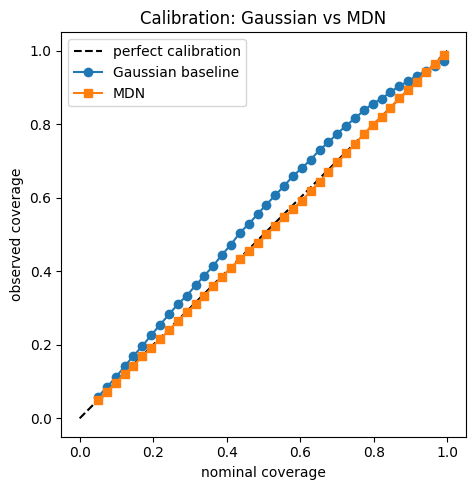

In [10]:
from scipy.stats import norm

nominal = np.linspace(0.05, 0.99, 40)

# Gaussian: empirical coverage at each nominal level
ks = norm.ppf(0.5 + nominal/2)
g_empirical = [np.mean(np.abs(yte - g_mu) <= k * g_sig) for k in ks]

# MDN: same nominal levels, but from the PIT values (already computed as `pit`)
m_empirical = [np.mean((pit > (0.5 - p/2)) & (pit < (0.5 + p/2))) for p in nominal]

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], 'k--', label="perfect calibration")
plt.plot(nominal, g_empirical, 'o-', label="Gaussian baseline")
plt.plot(nominal, m_empirical, 's-', label="MDN")
plt.xlabel("nominal coverage"); plt.ylabel("observed coverage")
plt.title("Calibration: Gaussian vs MDN")
plt.legend(); plt.gca().set_aspect("equal")
plt.tight_layout(); plt.show()

We can clearly see that side by side, the MDN did better with a more calibrated uncertainty, supporting the flexible posterior gives much advantage to this model and better fit this type of problem.

### Evaluation 3 - Does the MDN find the second solution?

Can the MDN trained model correctly handle test quasars it's never seen?

We rerun the training-free neighbour check on the **test set** to flag genuinely degenerate objects.
Then, for each one, we plot:
- The neighbour-redshift empirical posterior.
- The MDN's learned $p(z\mid\text{colors})$.
- The Gaussian baseline's posterior, together.

test-set multi-modal fraction: 20.2%  (1512 of 7500 quasars)


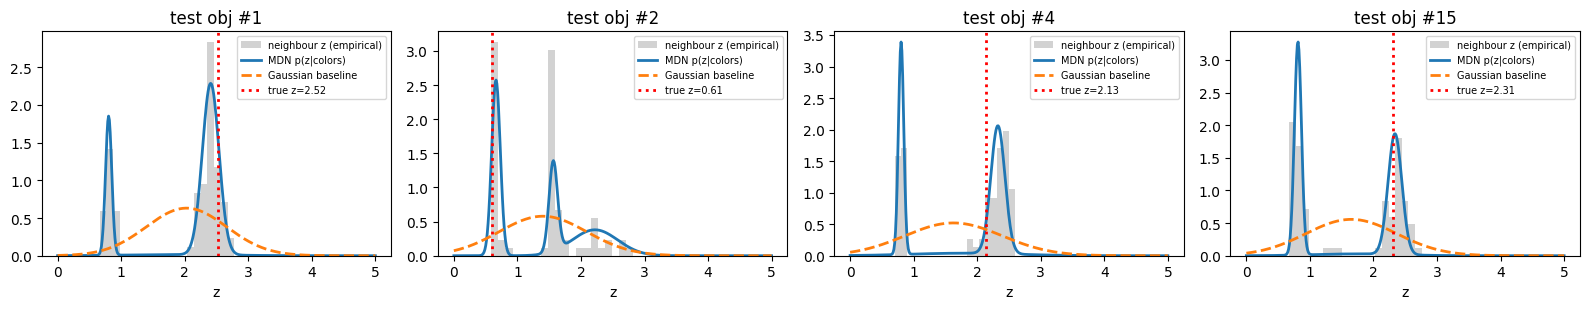

In [ ]:
def multimodality_report_test(colors_tr, zspec_tr, colors_te, zspec_te, mu_c, sd_c, k=80, gap=0.5, mass=0.15):
    # standardization
    Cs_tr = (colors_tr - mu_c) / (sd_c + 1e-9)
    Cs_te = (colors_te - mu_c) / (sd_c + 1e-9)
    # checking neighbores in training set for quasars in testing set
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(Cs_tr).kneighbors(Cs_te) # indices of 81 closest neighbores for wach quasar
    flags = np.zeros(len(zspec_te), bool)
    examples = []
    for q in range(len(zspec_te)):
        # skip first entry, giving 80 neighbors for each quasar of the testing set, from the training set. each neighbore with its own redshift.
        # then sort those 80 redshifts from smallest to largest. zn = 80 sorted redshift numbers.
        zn = np.sort(zspec_tr[idx[q, 1:]])
        # the gap between each consecutive pair of sorted redshifts
        g = np.diff(zn)
        # where the single biggest gap is
        p = g.argmax()
        # bimodality conditions + flagging + drawing examples
        if g[p] > gap and min(p + 1, len(zn) - (p + 1)) >= mass * k:
            flags[q] = True
            examples.append(q)
    return flags, examples, idx

# actually calling the function using the indices of training and testing sets
flags_te, examples_te, idx_te = multimodality_report_test(colors[tr], zspec[tr], colors[te], zspec[te], mu_c, sd_c)
print(f"test-set multi-modal fraction: {flags_te.mean():.1%}  ({flags_te.sum()} of {len(flags_te)} quasars)")

# plotting a few examples
show = examples_te[:4]
fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 3.2), squeeze=False)
for ax, q in zip(axes[0], show):
    # horizontal axis is redshifts
    zn = zspec[tr][idx_te[q, 1:]]
    # histogram of neighbores of certain redshift from the testing set
    ax.hist(zn, bins=20, density=True, alpha=0.35, color='gray', label="neighbour z (empirical)")
    zgrid = np.linspace(0, 5, 400)
    # plotting mdn predictions of peaks - pull out the K numbers for this one quasar (q) from the arrays computed back when we did 'mdn(Xte_t) 
    dens_mdn = (pi[q][None,:] * (1/np.sqrt(2*np.pi*mdn_var[q][None,:])) * np.exp(-0.5*(zgrid[:,None]-mdn_mu_np[q][None,:])**2/mdn_var[q][None,:])).sum(1)
    ax.plot(zgrid, dens_mdn, lw=2, label="MDN p(z|colors)")
    # plotting Gaussian baseline predictions
    dens_g = (1/np.sqrt(2*np.pi*g_sig[q]**2)) * np.exp(-0.5*(zgrid-g_mu[q])**2/g_sig[q]**2)
    ax.plot(zgrid, dens_g, lw=2, ls='--', label="Gaussian baseline")
    ax.axvline(zspec[te][q], color='r', ls=':', lw=2, label=f"true z={zspec[te][q]:.2f}")
    ax.set_xlabel("z"); ax.set_title(f"test obj #{q}"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


In 3 out of the four examples shown, the MDN's learned mixture posterior correctly separates into two peaks matching the empirical neighbor distribution, identifying which branch (low-z or high-z) the true redshift falls into, landing near the correctly-identified branch each time - while the Gaussian baseline's single symmetric bump spans the full gap between clusters in every case, unable to represent either branch specifically. This is consistent with the training-free multimodality check, providing two independent pieces of evidence for the same underlying color-redshift degeneracy.

However, it's worth mentioning that in one of the shown examples (object 4) the MDN's high-z peak is shifted slightly from the true value (peak near $~2.2-2.3$ vs. true $z=2.13$) - although the model correctly detects that a high-z solution does in fact exist and roughly where it sits, it doesn't place the peak with as much precision as it shown in other examples. This indicates that even though a flexible posterior is able to capture the right overall shape well enough (bimodality, correct branch), exact numerical accuracy isn't guaranteed on every individual object.

---
## Hyperparameters

**Architecture**
- `hidden=64` for both models (`PosteriorNet` and `MixtureDensityNet`), so the comparison is about the posterior type (single Gaussian vs. mixture), not model size.
- `K=3` components for the MDN - the neighbor check found 2 clear branches, and 3 gives a bit of headroom without adding collapse risk.
- MDN component means start at the 10th/50th/90th percentile of training redshifts instead of randomly, so the components don't all converge to the same solution.

**Optimisation** (same for both models)
- Optimiser: Adam, `lr=2e-3`, weight decay `wd=1e-5` (also helps prevent variance collapse in the MDN).
- Batch size: `batch=512`.
- Max epochs: Up to `epochs=600`, but early stopping usually ends training sooner.
- Early stopping (`patience=50`) plus a learning-rate scheduler that kicks in first when validation loss stalls.

---
## Self-assessment

**What each model learned.** Both models learned a genuine, nonlinear mapping from 'ugriz' colors to redshift - the Gaussian baseline's point predictions and the MDN's mixture mean both track the true redshift reasonably well on the majority of quasars ($MAE(Δz) \approx 0.15$, outlier fraction $\approx 0.3$ for both models). But the two differ sharply on the roughly $20%$ of quasars whose colors are genuinely consistent with two very different redshifts. The Gaussian, constrained to a single symmetric bump, cannot represent that: it responds by spreading its uncertainty across the entire gap between the two real solutions, including redshifts that essentially no similar-colored quasar actually has. The MDN, without ever being told which objects are degenerate, learned mixture weights well enough that it correctly split probability mass into two separated peaks - specifically on the objects the independent, training-free nearest-neighbor check also flagged as bimodal. The same low-z/high-z structure identified two different ways is the strongest evidence here that the MDN is capturing a real physical effect, not over-fitting noise.

**What the uncertainty means, and whether I trust it.** The calibration check surfaced a genuine, non-obvious finding: the Gaussian baseline is *underconfident*, not overconfident - its $1\sigma$ interval contains the truth 76% of the time against a nominal 68% ($2\sigma$ coverage is close to correct, 95% vs. 95% wanted). This model is safe but wasteful, and it gives no way to tell *which* objects actually needed that extra width. The MDN's PIT histogram is close to flat, with no U-shape (no variance-collapse overconfidence), meaning it reaches comparable calibration without paying that blanket-padding cost - it can be narrow on easy objects and split its mass on hard ones instead of being uniformly cautious. I trust the MDN's mixture weights as a more meaningful signal of "how many plausible solutions does this object have" than the Gaussian's $\sigma$, which only ever says "how wide is my one guess."

**Where it fails, and why.** The worked examples aren't uniformly perfect. In most flagged objects the MDN's peaks land close to the true redshift, correctly identifying which branch (low-z or high-z) is correct. But in object #4, the relevant peak is slightly shifted from the true value, which means that the model correctly detects that a solution does exists, in roughly the right region, but doesn't place it with exact precision. This is a significant limit - a flexible posterior that gets the right overall *shape* (correct number of modes, correct rough locations) is not the same as a model being numerically exact on every individual object.

**When the full posterior matters vs. when a point estimate suffices.** For the majority of quasars - those whose colors don't sit near the degenerate region - a point estimate with a reasonable error bar is essentially sufficient. The full, flexible posterior is found to be useful specifically for around $20%$ of objects flagged as multi-modal, where a single number and an error bar are actively misleading.